# 23 - Carbon Emissions and Temperature: what the two series do and do not show
**Topic:** Data Visualization  |  **Reference:** "Carbon Emissions Impact Analysis with Python" (amanxai.com, Nov 2024)

**Question.** How has atmospheric CO2 changed since 1958, how has surface temperature changed since 1961, and how closely are they linked?

**Reference method:** merge a monthly CO2 table with annual country temperatures, draw a correlation heat map (reported r = 0.96), fit trend lines, and simulate "what-if" scenarios with a regression.
**What I check first:** (1) the CO2 file contains **two different series stacked in one column**; (2) a correlation between two series that both trend upward is almost guaranteed to be high and says little by itself, so I compare correlations of the **levels, of the detrended series and of the year-to-year changes**; (3) the **speed** of change (acceleration of CO2, a break in the warming rate); (4) a **held-out test** of the "what-if" regression.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)
co = pd.read_csv("../_data/carbon/carbon_emmission.csv"); tp = pd.read_csv("../_data/carbon/temperature.csv")
print("CO2 file:", co.shape, "| countries in it:", co.Country.unique().tolist(), "| temperature file:", tp.shape); co.head(3)

CO2 file: (1570, 4) | countries in it: ['World'] | temperature file: (225, 66)


,ObjectId,Country,Date,Value
0,1,World,1958M03,315.70
1,2,World,1958M04,317.45
2,3,World,1958M05,317.51


## 2. Data audit

In [2]:
big, small = co[co.Value > 100], co[co.Value < 100]
print("rows with Value > 100: %d, with Value < 100: %d | (Country, Date) pairs that are duplicated: %d" % (len(big), len(small), co.duplicated(["Country", "Date"]).sum()))
print("series A (Value > 100): %s to %s, range %.1f-%.1f, one value per month: %s" % (big.Date.iloc[0], big.Date.iloc[-1], big.Value.min(), big.Value.max(), big.Date.is_unique))
print("series B (Value < 100): %s to %s, range %.2f-%.2f, one value per month: %s" % (small.Date.iloc[0], small.Date.iloc[-1], small.Value.min(), small.Value.max(), small.Date.is_unique))
Aser = big.set_index("Date").Value; Bser = small.drop_duplicates("Date").set_index("Date").Value; pct12 = (Aser.pct_change(12) * 100).dropna(); jj = pd.concat([pct12.rename("12-month % change of series A"), Bser.rename("series B")], axis=1).dropna()
print("series B vs the 12-month PERCENTAGE change of series A over %d months: correlation %.3f, mean absolute difference %.4f -> series B is the year-over-year growth of CO2 in percent" % (len(jj), jj.corr().iloc[0, 1], (jj.iloc[:, 0] - jj.iloc[:, 1]).abs().mean()))
print("series B in 1959-1961 vs 2020-2023 (mean, %% per year):", small.assign(year=small.Date.str[:4].astype(int)).groupby("year").Value.mean().round(2).loc[[1959, 1960, 1961, 2020, 2021, 2022, 2023]].to_dict())
yrs = [c for c in tp.columns if c.startswith("F")]; tp_long = tp.melt(id_vars=["Country", "ISO3"], value_vars=yrs, var_name="year", value_name="dT"); tp_long["year"] = tp_long.year.str[1:].astype(int)
print("\ntemperature file: %d rows (all carry an ISO3 code; one of them, WLD, is the 'World' aggregate) | years %d-%d | missing values %.1f%%" % (len(tp), tp_long.year.min(), tp_long.year.max(), tp_long.dT.isna().mean() * 100))

rows with Value > 100: 790, with Value < 100: 780 | (Country, Date) pairs that are duplicated: 779
series A (Value > 100): 1958M03 to 2023M12, range 312.4-424.0, one value per month: True
series B (Value < 100): 1959M03 to 2024M01, range -0.10-1.06, one value per month: False
series B vs the 12-month PERCENTAGE change of series A over 778 months: correlation 1.000, mean absolute difference 0.0024 -> series B is the year-over-year growth of CO2 in percent
series B in 1959-1961 vs 2020-2023 (mean, %% per year): {1959: 0.24, 1960: 0.29, 1961: 0.23, 2020: 0.62, 2021: 0.53, 2022: 0.51, 2023: 0.61}



temperature file: 225 rows (all carry an ISO3 code; one of them, WLD, is the 'World' aggregate) | years 1961-2022 | missing values 10.7%


**Reading it.**
* **The CO2 file holds two different series stacked in one column.** 790 values between 312 and 424 are the monthly CO2 **concentration in ppm** (March 1958 to December 2023, no missing months). The other 780 values (between -0.1 and 1.06, from March 1959) are the **year-over-year growth of that concentration in percent**: their correlation with the 12-month percentage change I compute from the first series is **1.000** (mean absolute difference 0.002). 779 (Country, Date) pairs are therefore duplicated. A merge that does not separate them mixes ppm and percent in one "CO2" column; any averages, correlations or models built on it would be meaningless.
* The temperature file has 225 rows, one of them (WLD) the "World" aggregate; 10.7% of the country-year values are missing, mainly for newer countries (South Sudan, Montenegro, Serbia and others have 43-50 missing years). The values behave like **changes in surface temperature in degrees C relative to a baseline period** (about 0 in the 1960s, 1.4 for the world by 2022); the file does not state the baseline.

**Handling.** Series A (values around 315-424) is the CO2 *concentration* in parts per million (ppm); series B (values from about 0 to 1) equals the **12-month percentage change of series A** (checked above, correlation 1.00), also monthly, starting 1959. I separate them by value (the two ranges do not overlap), so the reference's merged "CO2" column would be a mix of both. For temperature I use the **World** row as the global series and all other rows as countries and territories.

## 3. CO2 concentration: trend, season and acceleration

months from 1958-03-01 to 2023-12-01: 790 | missing months in the series: 0


mean annual increase (ppm per year) by decade: {'1960s': 0.86, '1970s': 1.22, '1980s': 1.64, '1990s': 1.53, '2000s': 1.91, '2010s': 2.4, '2020-2023': 2.36}
seasonal swing (peak-to-trough of the STL seasonal component): 7.1 ppm | CO2 in 1959: 316.0 ppm, in 2023: 421.1 ppm (+33%)


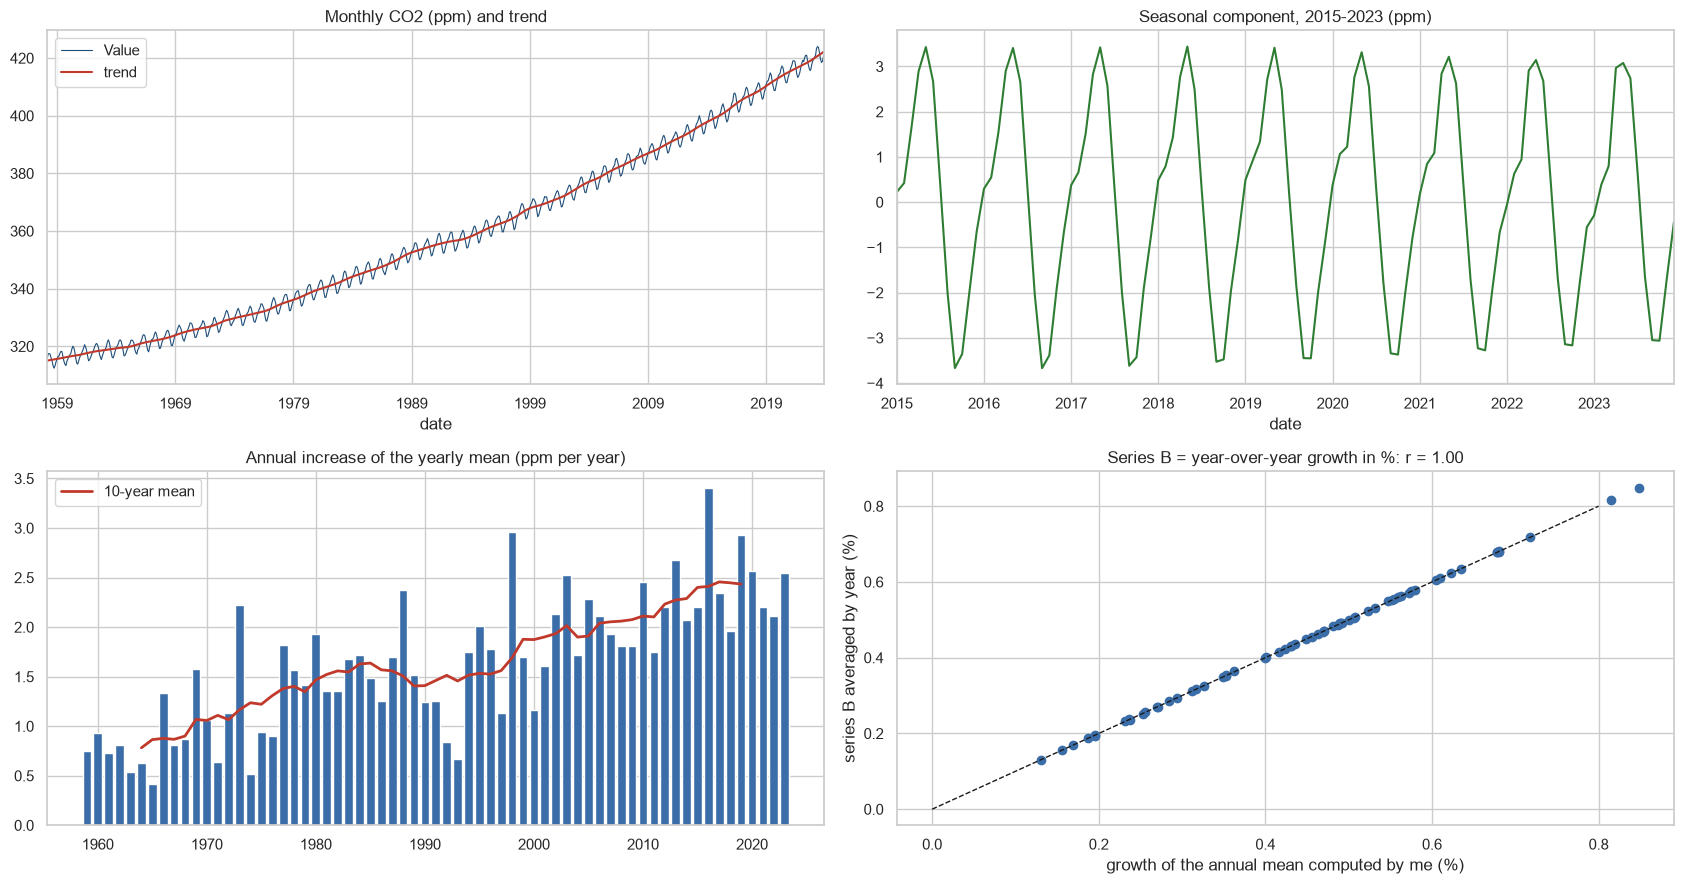

In [3]:
A = big.assign(date=pd.to_datetime(big.Date.str.replace("M", "-") + "-01")).set_index("date").Value.asfreq("MS")
print("months from %s to %s: %d | missing months in the series: %d" % (A.index[0].date(), A.index[-1].date(), len(A), A.isna().sum()))
Ai = A.interpolate(); stl = STL(Ai, period=12, robust=True).fit(); ann = Ai.groupby(Ai.index.year).mean(); ann = ann[ann.index <= 2023]
growth = ann.diff().dropna()
dec = pd.Series({f"{d}s": growth[(growth.index >= d) & (growth.index < d + 10)].mean() for d in range(1960, 2020, 10)}); dec["2020-2023"] = growth.loc[2020:2023].mean()
print("mean annual increase (ppm per year) by decade:", dec.round(2).to_dict())
print("seasonal swing (peak-to-trough of the STL seasonal component): %.1f ppm | CO2 in 1959: %.1f ppm, in 2023: %.1f ppm (+%.0f%%)" % (stl.seasonal.max() - stl.seasonal.min(), ann.loc[1959], ann.loc[2023], (ann.loc[2023] / ann.loc[1959] - 1) * 100))
fig, ax = plt.subplots(2, 2, figsize=(17, 9))
Ai.plot(ax=ax[0, 0], color="#1f4e79", lw=.8); stl.trend.plot(ax=ax[0, 0], color="#c0392b", lw=1.5, label="trend"); ax[0, 0].set_title("Monthly CO2 (ppm) and trend"); ax[0, 0].legend()
stl.seasonal["2015":"2023"].plot(ax=ax[0, 1], color="#2e7d32"); ax[0, 1].set_title("Seasonal component, 2015-2023 (ppm)")
ax[1, 0].bar(growth.index, growth.values, color="#3b6ea8"); ax[1, 0].set_title("Annual increase of the yearly mean (ppm per year)"); ax[1, 0].plot(growth.index, growth.rolling(10, center=True).mean(), color="#c0392b", lw=2, label="10-year mean"); ax[1, 0].legend()
prov = small.assign(year=small.Date.str[:4].astype(int)).groupby("year").Value.mean(); cmp_ = pd.concat([(ann.pct_change() * 100).rename("my annual-mean growth (%)"), prov.rename("series B, yearly mean (%)")], axis=1).dropna()
ax[1, 1].scatter(cmp_.iloc[:, 0], cmp_.iloc[:, 1], color="#3b6ea8"); lim = [0, 0.8]; ax[1, 1].plot(lim, lim, "k--", lw=1); ax[1, 1].set_xlabel("growth of the annual mean computed by me (%)"); ax[1, 1].set_ylabel("series B averaged by year (%)"); ax[1, 1].set_title("Series B = year-over-year growth in %%: r = %.2f" % cmp_.corr().iloc[0, 1])
plt.tight_layout(); plt.show()

**Reading it.**
* CO2 rose from 316.0 ppm (annual mean 1959) to **421.1 ppm in 2023 (+33%)**. On top of the trend there is a regular yearly cycle of about **7 ppm peak to trough** (Northern Hemisphere vegetation), so monthly values must be compared with the same month or seasonally adjusted.
* The yearly increase is **speeding up**: on average 0.86 ppm/year in the 1960s, 1.22 in the 1970s, 1.64 in the 1980s, 1.53 in the 1990s, 1.91 in the 2000s, **2.40 in the 2010s** and 2.36 in 2020-2023. It is not a smooth rise (1990s lower than the 1980s).
* The last panel confirms that "series B" is the growth in percent of the concentration, not a count of ppm (r = 1.00 against my own computed growth; the points lie on the diagonal).

In [4]:
t = (ann.index - 1958).to_numpy().astype(float); tr = ann.index <= 2012; te = ~tr
X1, X2 = sm.add_constant(t), sm.add_constant(np.c_[t, t ** 2])
m1 = sm.OLS(ann.values[tr], X1[tr]).fit(); m2 = sm.OLS(ann.values[tr], X2[tr]).fit()
rm = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
print("fit on 1958-2012, test on 2013-2023 (annual mean CO2, ppm):")
print("  linear trend: RMSE %.2f ppm | quadratic trend: RMSE %.2f ppm | 2023 actual %.1f, linear predicts %.1f, quadratic predicts %.1f" % (rm(m1.predict(X1[te]), ann.values[te]), rm(m2.predict(X2[te]), ann.values[te]), ann.loc[2023], m1.predict(X1[te])[-1], m2.predict(X2[te])[-1]))
full = sm.OLS(ann.values, X2).fit(cov_type="HAC", cov_kwds={"maxlags": 5}); print("quadratic coefficient on all years: %.4f ppm/yr^2 (95%% CI %.4f to %.4f) -> the annual increase grows by about %.2f ppm per decade" % (full.params[2], *full.conf_int()[2], 2 * full.params[2] * 10))

fit on 1958-2012, test on 2013-2023 (annual mean CO2, ppm):
  linear trend: RMSE 12.16 ppm | quadratic trend: RMSE 1.72 ppm | 2023 actual 421.1, linear predicts 404.6, quadratic predicts 418.9
quadratic coefficient on all years: 0.0132 ppm/yr^2 (95% CI 0.0121 to 0.0142) -> the annual increase grows by about 0.26 ppm per decade


**Reading it.** To test whether the acceleration is real I fitted a straight line and a parabola to 1958-2012 and predicted 2013-2023. The straight line is **12.2 ppm off on average** (it predicts 404.6 ppm for 2023, against 421.1 observed); the parabola is **1.7 ppm off** (418.9 for 2023). The quadratic coefficient on all years is 0.0132 ppm per year squared (95% interval 0.0121 to 0.0142), i.e. the yearly increase grows by about 0.26 ppm each decade. A parabola cannot continue forever and is a description of the past, not a physical model; but for the last decade it clearly predicts better than a constant rate.

## 4. Temperature: global trend and a possible break

World, 1961-2022: warming trend 0.279 deg C per decade (95% CI 0.237 to 0.322) | change from 1961-1970 mean (-0.00) to 2013-2022 mean (1.39): +1.39 deg C
best single break in slope (piecewise linear): around 1975 | slope before -0.039 deg C/decade, after 0.330 deg C/decade | SSE improvement over one straight line: 25%



185 countries with at least 40 years of data | share warming: 99% | median 0.24, range -0.06 to 0.42 deg C/decade
fastest: [['Finland', 0.42], ['Kuwait', 0.41], ['Bahrain, Kingdom of', 0.41], ['Austria', 0.41], ['Sweden', 0.39], ['Germany', 0.39], ['Switzerland', 0.39], ['Liechtenstein', 0.39]]
slowest: [['Norfolk Island', 0.11], ['Cook Islands', 0.08], ['Botswana', 0.07], ['Zimbabwe', 0.06], ['Pitcairn Islands', -0.06]]


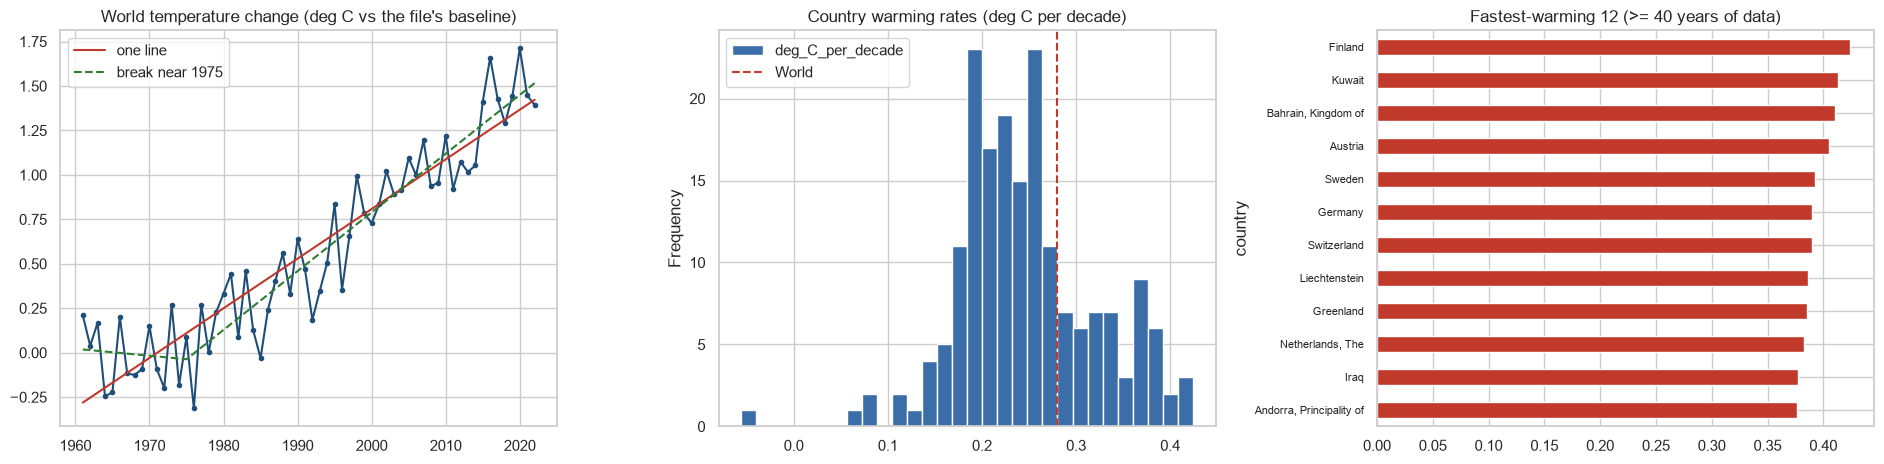

In [5]:
W = tp[tp.Country == "World"][yrs].iloc[0]; W.index = [int(c[1:]) for c in W.index]; W = W.astype(float)
X = sm.add_constant(W.index.values - 1961.0); ols = sm.OLS(W.values, X).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print("World, 1961-2022: warming trend %.3f deg C per decade (95%% CI %.3f to %.3f) | change from 1961-1970 mean (%.2f) to 2013-2022 mean (%.2f): +%.2f deg C" % (ols.params[1] * 10, *ols.conf_int()[1] * 10, W.loc[1961:1970].mean(), W.loc[2013:2022].mean(), W.loc[2013:2022].mean() - W.loc[1961:1970].mean()))
best = None
for b in range(1975, 2008):
    Xb = sm.add_constant(np.c_[W.index.values - 1961.0, np.maximum(0, W.index.values - b)]); m = sm.OLS(W.values, Xb).fit()
    if best is None or m.ssr < best[1].ssr: best = (b, m)
b, mb = best; pre, post = mb.params[1] * 10, (mb.params[1] + mb.params[2]) * 10
print("best single break in slope (piecewise linear): around %d | slope before %.3f deg C/decade, after %.3f deg C/decade | SSE improvement over one straight line: %.0f%%" % (b, pre, post, (1 - mb.ssr / ols.ssr) * 100))
rows = []
for _, r in tp[tp.Country != "World"].iterrows():
    y_ = r[yrs].astype(float).to_numpy(); ok = ~np.isnan(y_)
    if ok.sum() >= 40: rows.append([r.Country, r.ISO3, np.polyfit(np.arange(62)[ok], y_[ok], 1)[0] * 10, ok.sum()])
CT = pd.DataFrame(rows, columns=["country", "iso3", "deg_C_per_decade", "years"]).sort_values("deg_C_per_decade", ascending=False)
print("\n%d countries with at least 40 years of data | share warming: %.0f%% | median %.2f, range %.2f to %.2f deg C/decade" % (len(CT), (CT.deg_C_per_decade > 0).mean() * 100, CT.deg_C_per_decade.median(), CT.deg_C_per_decade.min(), CT.deg_C_per_decade.max()))
print("fastest:", CT.head(8)[["country", "deg_C_per_decade"]].round(2).values.tolist()); print("slowest:", CT.tail(5)[["country", "deg_C_per_decade"]].round(2).values.tolist())
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].plot(W.index, W.values, "o-", color="#1f4e79", ms=3); ax[0].plot(W.index, ols.predict(X), color="#c0392b", label="one line"); xb = sm.add_constant(np.c_[W.index.values - 1961.0, np.maximum(0, W.index.values - b)]); ax[0].plot(W.index, mb.predict(xb), color="#2e7d32", ls="--", label=f"break near {b}"); ax[0].set_title("World temperature change (deg C vs the file's baseline)"); ax[0].legend()
CT.deg_C_per_decade.plot.hist(bins=30, ax=ax[1], color="#3b6ea8"); ax[1].axvline(ols.params[1] * 10, color="#c0392b", ls="--", label="World"); ax[1].legend(); ax[1].set_title("Country warming rates (deg C per decade)")
CT.head(12).iloc[::-1].set_index("country").deg_C_per_decade.plot.barh(ax=ax[2], color="#c0392b"); ax[2].set_title("Fastest-warming 12 (>= 40 years of data)"); ax[2].tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

**Reading it.**
* The world's surface temperature change rose by about **0.28 degrees C per decade** over 1961-2022 (95% interval 0.24 to 0.32, with robust errors), from about 0.0 in 1961-70 to 1.39 in 2013-2022 (**+1.39 degrees C** between the 10-year means).
* A single straight line is not a good description: the best two-piece line breaks near **1975**, with a slope of about **-0.04 degrees C/decade before and +0.33 after** (a 25% smaller error than one line). The break year sits at the edge of the range I searched (1975-2007), so it should be read as "the warming started in the 1970s", not as a precise date.
* **Almost every country warmed:** 99% of 185 countries with at least 40 years of data have a positive trend; the median is 0.24 degrees C per decade and the range -0.06 to 0.42. The fastest-warming are Finland (0.42), Kuwait and Bahrain (0.41), Austria (0.41), then Sweden, Germany, Switzerland and Liechtenstein (0.39). The slowest are mostly small islands and southern Africa (Norfolk Island 0.11, Cook Islands 0.08, Botswana 0.07, Zimbabwe 0.06; Pitcairn -0.06). These are simple per-country straight-line fits, with different numbers of missing years, so they do not have uncertainty intervals.

## 5. How strong is the link between CO2 and temperature, and what can this data say about it?
Annual mean CO2 against the World temperature change, 1961-2022. Three correlations on the same pair: of the **levels** (what the reference reports), of the series after removing **each one's own linear time trend**, and of the **year-to-year changes**.

correlation of annual mean CO2 and World temperature change (n=62 years):
levels                                          0.94
after removing each series' linear trend        0.47
year-to-year changes                            0.31
year-to-year changes, 10-year moving average    0.41

regression of temperature change on CO2: 0.0170 deg C per ppm (95% HAC CI 0.0155 to 0.0185), i.e. 1.70 deg C per +100 ppm (CI 1.55 to 1.85), R2 0.89


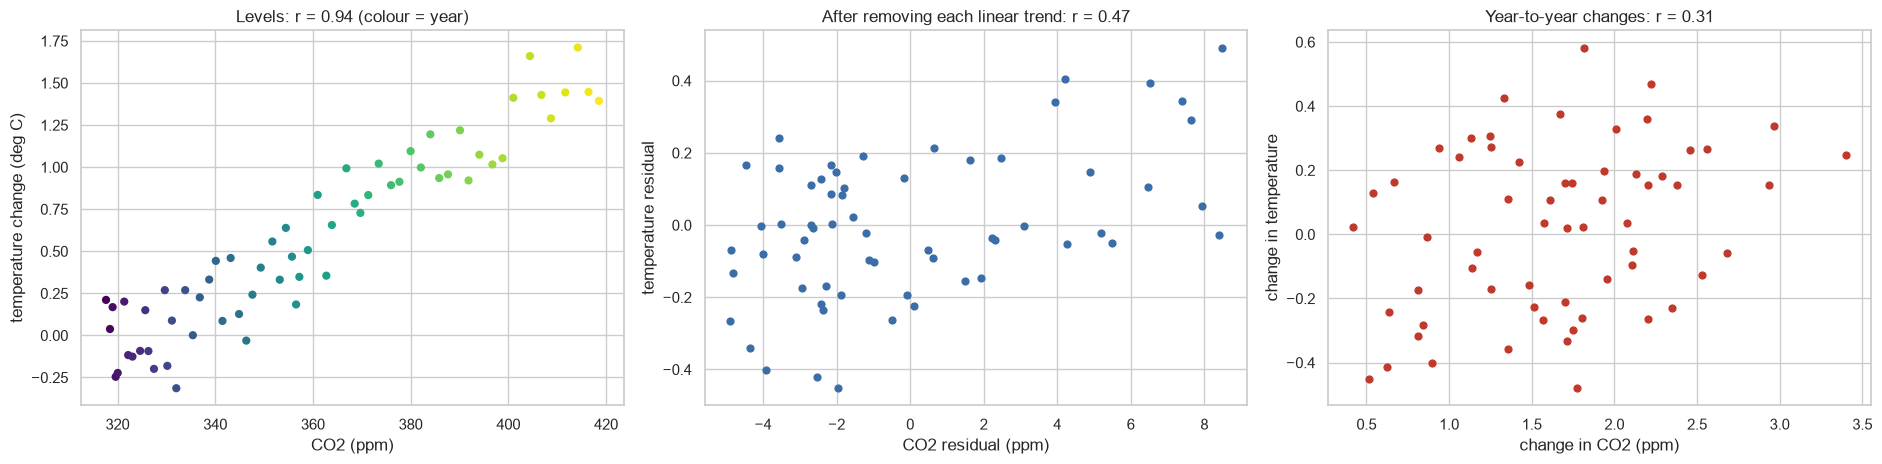

In [6]:
d = pd.concat([ann.rename("co2"), W.rename("dT")], axis=1).dropna().loc[1961:2022]; yr = d.index.values.astype(float)
res_co2 = d.co2 - np.polyval(np.polyfit(yr, d.co2, 1), yr); res_dT = d.dT - np.polyval(np.polyfit(yr, d.dT, 1), yr); dd = d.diff().dropna()
cor = pd.Series({"levels": d.co2.corr(d.dT), "after removing each series' linear trend": res_co2.corr(res_dT), "year-to-year changes": dd.co2.corr(dd.dT), "year-to-year changes, 10-year moving average": dd.rolling(10).mean().dropna().co2.corr(dd.rolling(10).mean().dropna().dT)})
print("correlation of annual mean CO2 and World temperature change (n=%d years):" % len(d)); print(cor.round(2).to_string())
b0, b1 = np.polyfit(d.co2, d.dT, 1); mm = sm.OLS(d.dT.values, sm.add_constant(d.co2.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 5}); ci = mm.conf_int()[1]
print("\nregression of temperature change on CO2: %.4f deg C per ppm (95%% HAC CI %.4f to %.4f), i.e. %.2f deg C per +100 ppm (CI %.2f to %.2f), R2 %.2f" % (mm.params[1], *ci, mm.params[1] * 100, *ci * 100, mm.rsquared))
fig, ax = plt.subplots(1, 3, figsize=(19, 4.8))
ax[0].scatter(d.co2, d.dT, c=d.index, cmap="viridis", s=24); ax[0].set_xlabel("CO2 (ppm)"); ax[0].set_ylabel("temperature change (deg C)"); ax[0].set_title("Levels: r = %.2f (colour = year)" % cor.iloc[0])
ax[1].scatter(res_co2, res_dT, color="#3b6ea8", s=24); ax[1].set_title("After removing each linear trend: r = %.2f" % cor.iloc[1]); ax[1].set_xlabel("CO2 residual (ppm)"); ax[1].set_ylabel("temperature residual")
ax[2].scatter(dd.co2, dd.dT, color="#c0392b", s=24); ax[2].set_title("Year-to-year changes: r = %.2f" % cor.iloc[2]); ax[2].set_xlabel("change in CO2 (ppm)"); ax[2].set_ylabel("change in temperature")
plt.tight_layout(); plt.show()

**Reading it.**
* **The reference's correlation is reproduced: 0.94 for the levels.** But both series trend upward, so a high correlation is nearly guaranteed. After removing each series' own linear time trend the correlation falls to **0.47**, and for year-to-year changes to **0.31** (0.41 with 10-year smoothing). The year-to-year link is weak because annual temperature has much natural variation (El Nino years, volcanic eruptions) that CO2 does not follow.
* The regression slope is 0.0170 degrees C per ppm (**1.70 degrees C per +100 ppm**, HAC 95% interval 1.55-1.85; R-squared 0.89). The interval is likely too narrow: regressing one trending series on another leaves strongly autocorrelated residuals with a few effective observations, and HAC errors only partly correct for this. The slope describes the association in 1961-2022; it cannot, by itself, separate the effect of CO2 from other things that also changed smoothly over the same years (the energy-balance physics that does connect them lies outside this data).

## 6. A fair test of the "what-if" regression
Train on 1961-2000, predict World temperature for 2001-2022 using (a) the **mean** of the training years, (b) a **time trend** only, (c) a regression on **CO2** (using the *observed* CO2, which is the best case for a what-if tool), and (d) **both**.

In [7]:
tr_ = d.index <= 2000; te_ = ~tr_; t_ = d.index.values - 1961.0
def fit_pred(cols):
    Xf = sm.add_constant(np.c_[tuple(cols)]) if len(cols) else np.ones((len(d), 1)); m = sm.OLS(d.dT.values[tr_], Xf[tr_]).fit(); return m.predict(Xf[te_])
preds = {"training mean": fit_pred([]), "time trend only": fit_pred([t_]), "CO2 only": fit_pred([d.co2.values]), "time trend + CO2": fit_pred([t_, d.co2.values])}
oos = pd.DataFrame({k: {"RMSE (deg C)": float(np.sqrt(np.mean((v - d.dT.values[te_]) ** 2))), "mean error (bias)": float(np.mean(v - d.dT.values[te_]))} for k, v in preds.items()}).T; print("test years 2001-2022 (22 values):"); print(oos.round(3).to_string())
scen = pd.DataFrame({"CO2 +10 ppm": 10, "CO2 +30 ppm": 30, "CO2 +50 ppm": 50}, index=["ppm"]).T; scen["central (deg C)"] = scen.ppm * mm.params[1]; scen["95% low"] = scen.ppm * ci[0]; scen["95% high"] = scen.ppm * ci[1]; print("\nwhat-if from the regression slope (association only):"); print(scen.round(2).to_string())

test years 2001-2022 (22 values):
                  RMSE (deg C)  mean error (bias)
training mean            0.974             -0.941
time trend only          0.332             -0.288
CO2 only                 0.176             -0.097
time trend + CO2         0.625              0.507

what-if from the regression slope (association only):
             ppm  central (deg C)  95% low  95% high
CO2 +10 ppm   10             0.17     0.16      0.18
CO2 +30 ppm   30             0.51     0.47      0.55
CO2 +50 ppm   50             0.85     0.78      0.92


**Reading it.** Predicting 2001-2022 from the years up to 2000: the training mean is off by 0.97 degrees C on average (the world warmed), a time trend 0.33, **CO2 alone 0.18 (best)**, and a time trend and CO2 *together* 0.63 (worse than either alone, with a +0.5 degree bias): the two predictors are almost perfectly correlated, so the fitted coefficients are unstable and extrapolate badly. The what-if table translates +10, +30 and +50 ppm into +0.17, +0.51 and +0.85 degrees C (with narrow intervals that I trust only as much as the caveat above). Used with care, a regression on CO2 is a reasonable *description* of the post-1960 relationship; as a scenario engine it is a straight-line extrapolation of two trending series and does not know about feedbacks, aerosols, or the lag of the ocean's response.

## 7. Save

In [8]:
d.reset_index(names="year").to_csv("model/annual_co2_temperature.csv", index=False); CT.to_csv("model/country_warming_rates.csv", index=False)
json.dump({"co2_decade_increase": dec.round(3).to_dict(), "world_trend_per_decade": float(ols.params[1] * 10), "trend_ci": [float(x) for x in ols.conf_int()[1] * 10], "break_year": int(b), "slope_pre": float(pre), "slope_post": float(post),
           "correlations": cor.round(3).to_dict(), "slope_deg_per_ppm": float(mm.params[1]), "slope_ci": [float(x) for x in ci], "oos": oos.round(3).to_dict("index")}, open("model/meta.json", "w"), indent=1); print(os.listdir("model"))

['annual_co2_temperature.csv', 'country_warming_rates.csv', 'meta.json']


## 8. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Data | merged two files | found two series stacked in the CO2 file (ppm and year-over-year %); separated them and checked the relationship (r = 1.000) |
| CO2 | trend line | trend, seasonal swing (7 ppm), acceleration (0.86 -> 2.4 ppm/yr; quadratic fit 1.7 ppm error vs 12.2 for a line on 2013-23) |
| Temperature | trend lines | World +0.28 degrees C/decade (CI 0.24-0.32), a change in slope near 1975, 99% of 185 countries warming |
| Link CO2-temperature | correlation 0.96 (levels) | 0.94 for levels, 0.47 after detrending, 0.31 for yearly changes; slope 1.7 degrees C per 100 ppm |
| What-if | regression scenarios | held-out test: CO2 alone RMSE 0.18 vs time trend 0.33; both together 0.63 (unstable) |

**What I learned.** (1) Check what is *in* a column: two series shared one. (2) A correlation between two trending series says little; compare detrended and differenced versions. (3) The acceleration of CO2 is visible and a model without it fails within a decade. (4) A what-if tool built on two collinear trending series needs a stated caveat.

**Limits.** Annual world means only; no baseline given for temperature; per-country slopes have no intervals and differing missing years; a regression on two trending series cannot establish cause (the physical mechanism is not tested here); the break year is at the edge of the search grid. **Next step:** add emissions data (not just concentration), ocean and volcanic indices, and a physically-based energy-balance model.